<sub>**The Annotated ML Handbook** · by Mahir Absar Khan</sub>

# Solutions: Parts V–VIII

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/solutions/solutions-parts-5-8.ipynb) &nbsp; [📚 Contents](../book/README.md)

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

# Solutions: Parts V–VIII

Worked solutions to the exercises in the machine-learning, deep-learning, research and debugging chapters. Exact scores depend on random splits; what matters is the method and the conclusion.

## Shared set-up · *Beginner*

**Imports used throughout this appendix**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine, load_iris, load_breast_cancer, load_digits, make_classification
from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, StratifiedKFold, KFold)
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyClassifier
from sklearn.metrics import root_mean_squared_error, recall_score, precision_score, balanced_accuracy_score
ins = pd.read_csv("insurance.csv")
print("ready", ins.shape)

ready (1000, 7)


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import numpy as np</code></td><td>Arrays.</td></tr>
<tr><td><code>import pandas as pd</code></td><td>Tables.</td></tr>
<tr><td><code>import matplotlib.pyplot as plt</code></td><td>Plots.</td></tr>
<tr><td><code>from sklearn.datasets import load_wine, load_iris, load_breast_cancer, load_digits, make_classification</code></td><td>Built-in data.</td></tr>
<tr><td><code>from sklearn.model_selection import (train_test_split, cross_val_score, cross_validate,</code></td><td>Splitting and CV...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;cross_val_predict, GridSearchCV, StratifiedKFold, KFold)</code></td><td>...and tuning.</td></tr>
<tr><td><code>from sklearn.pipeline import make_pipeline, Pipeline</code></td><td>Pipelines.</td></tr>
<tr><td><code>from sklearn.compose import ColumnTransformer, TransformedTargetRegressor</code></td><td>Column routing; target transforms.</td></tr>
<tr><td><code>from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures</code></td><td>Preprocessing.</td></tr>
<tr><td><code>from sklearn.impute import SimpleImputer</code></td><td>Missing values.</td></tr>
<tr><td><code>from sklearn.linear_model import LogisticRegression, Ridge</code></td><td>Linear models.</td></tr>
<tr><td><code>from sklearn.neighbors import KNeighborsClassifier</code></td><td>kNN.</td></tr>
<tr><td><code>from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier</code></td><td>Ensembles.</td></tr>
<tr><td><code>from sklearn.tree import DecisionTreeRegressor</code></td><td>Single tree.</td></tr>
<tr><td><code>from sklearn.dummy import DummyClassifier</code></td><td>Baseline.</td></tr>
<tr><td><code>from sklearn.metrics import root_mean_squared_error, recall_score, precision_score, balanced_accuracy_score</code></td><td>Metrics.</td></tr>
<tr><td><code>ins = pd.read_csv(&quot;insurance.csv&quot;)</code></td><td>The practice dataset.</td></tr>
<tr><td><code>print(&quot;ready&quot;, ins.shape)</code></td><td>Check.</td></tr>
</table>
</details>

## [Chapter 19](../notebooks/part-5-scikit-learn/19-sklearn-concepts.ipynb): ML concepts and the scikit-learn API

**Exercise 1: three models on the wine data**

In [3]:
Xw, yw = load_wine(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xw, yw, stratify=yw, random_state=0)
for name, m in [("Dummy", DummyClassifier()), ("kNN", make_pipeline(StandardScaler(), KNeighborsClassifier())),
                ("RandomForest", RandomForestClassifier(random_state=0))]:
    print(f"{name:<13}", round(m.fit(Xtr, ytr).score(Xte, yte), 3))

Dummy         0.4
kNN           0.933
RandomForest  1.0


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>Xw, yw = load_wine(return_X_y=True)</code></td><td>178 wines, 3 classes.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xw, yw, stratify=yw, random_state=0)</code></td><td>Stratified split.</td></tr>
<tr><td><code>for name, m in [(&quot;Dummy&quot;, DummyClassifier()), (&quot;kNN&quot;, make_pipeline(StandardScaler(), KNeighborsClassifier())),</code></td><td>Baseline and scaled kNN...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(&quot;RandomForest&quot;, RandomForestClassifier(random_state=0))]:</code></td><td>...and a forest.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;{name:&lt;13}&quot;, round(m.fit(Xtr, ytr).score(Xte, yte), 3))</code></td><td>Fit, then test accuracy.</td></tr>
</table>
</details>

**Exercise 2: Ridge tames a degree-15 polynomial**

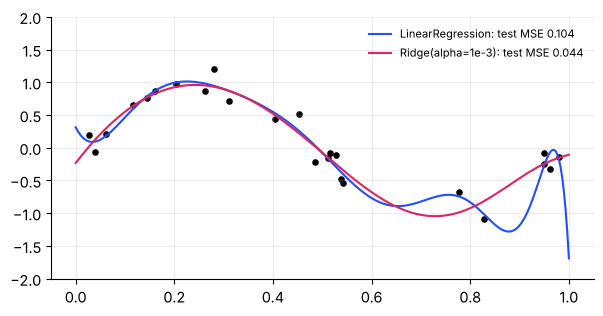

In [4]:
from sklearn.linear_model import LinearRegression
rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 1, 40)); y = np.sin(2 * np.pi * x) + rng.normal(0, 0.25, 40)
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.4, random_state=3)
grid = np.linspace(0, 1, 300).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.scatter(x_tr, y_tr, s=14, color="k")
for name, reg in [("LinearRegression", LinearRegression()), ("Ridge(alpha=1e-3)", Ridge(alpha=1e-3))]:
    m = make_pipeline(PolynomialFeatures(15), StandardScaler(), reg).fit(x_tr.reshape(-1, 1), y_tr)
    ax.plot(grid, m.predict(grid), label=f"{name}: test MSE {np.mean((m.predict(x_te.reshape(-1, 1)) - y_te) ** 2):.3f}")
ax.set_ylim(-2, 2); ax.legend(fontsize=8); plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.linear_model import LinearRegression</code></td><td>Unregularised fit.</td></tr>
<tr><td><code>rng = np.random.default_rng(1)</code></td><td>Same recipe as the chapter.</td></tr>
<tr><td><code>x = np.sort(rng.uniform(0, 1, 40)); y = np.sin(2 * np.pi * x) + rng.normal(0, 0.25, 40)</code></td><td>Noisy sine.</td></tr>
<tr><td><code>x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.4, random_state=3)</code></td><td>Split.</td></tr>
<tr><td><code>grid = np.linspace(0, 1, 300).reshape(-1, 1)</code></td><td>For drawing curves.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.4))</code></td><td>New figure.</td></tr>
<tr><td><code>ax.scatter(x_tr, y_tr, s=14, color=&quot;k&quot;)</code></td><td>Training points.</td></tr>
<tr><td><code>for name, reg in [(&quot;LinearRegression&quot;, LinearRegression()), (&quot;Ridge(alpha=1e-3)&quot;, Ridge(alpha=1e-3))]:</code></td><td>Two models.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m = make_pipeline(PolynomialFeatures(15), StandardScaler(), reg).fit(x_tr.reshape(-1, 1), y_tr)</code></td><td>Scaling makes the penalty treat all powers fairly.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.plot(grid, m.predict(grid), label=f&quot;{name}: test MSE {np.mean((m.predict(x_te.reshape(-1, 1)) - y_te) ** 2):.3f}&quot;)</code></td><td>Curve with its test error.</td></tr>
<tr><td><code>ax.set_ylim(-2, 2); ax.legend(fontsize=8); plt.show()</code></td><td>Limits, legend, draw.</td></tr>
</table>
</details>

**Exercise 3: accuracy depends on the split**

In [5]:
Xi, yi = load_iris(return_X_y=True)
accs = [KNeighborsClassifier().fit(a, c).score(b, d)
        for a, b, c, d in (train_test_split(Xi, yi, test_size=0.25, stratify=yi, random_state=s) for s in range(5))]
print(np.round(accs, 3), "range:", round(max(accs) - min(accs), 3))

[1.    0.947 1.    0.947 0.974] range: 0.053


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>Xi, yi = load_iris(return_X_y=True)</code></td><td>Iris.</td></tr>
<tr><td><code>accs = [KNeighborsClassifier().fit(a, c).score(b, d)</code></td><td>Fit and score...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;for a, b, c, d in (train_test_split(Xi, yi, test_size=0.25, stratify=yi, random_state=s) for s in range(5))]</code></td><td>...on five different splits.</td></tr>
<tr><td><code>print(np.round(accs, 3), &quot;range:&quot;, round(max(accs) - min(accs), 3))</code></td><td>Several points of difference from the split alone.</td></tr>
</table>
</details>

## [Chapter 20](../notebooks/part-5-scikit-learn/20-sklearn-preprocessing.ipynb): Preprocessing and pipelines

**Exercises 1 and 2: log target and polynomial features**

In [6]:
X, y = ins.drop(columns="charges"), ins["charges"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
def make_pre(poly=False):
    steps = [SimpleImputer(strategy="median"), StandardScaler()] + ([PolynomialFeatures(2, include_bias=False)] if poly else [])
    return ColumnTransformer([("num", make_pipeline(*steps), ["age", "bmi", "children"]),
                              ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ["sex", "smoker", "region"])])
base = Pipeline([("pre", make_pre()), ("m", Ridge())])
logt = TransformedTargetRegressor(regressor=Pipeline([("pre", make_pre()), ("m", Ridge())]), func=np.log1p, inverse_func=np.expm1)
poly = Pipeline([("pre", make_pre(poly=True)), ("m", Ridge())])
for name, m in [("plain", base), ("log target", logt), ("poly numeric", poly)]:
    m.fit(Xtr, ytr)
    print(f"{name:<13} R2 = {m.score(Xte, yte):.4f}")
print("features with poly:", poly.named_steps["pre"].get_feature_names_out().size)

plain         R2 = 0.9311
log target    R2 = 0.8823
poly numeric  R2 = 0.9340
features with poly: 15


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>X, y = ins.drop(columns=&quot;charges&quot;), ins[&quot;charges&quot;]</code></td><td>Features and target.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;steps = [SimpleImputer(strategy=&quot;median&quot;), StandardScaler()] + ([PolynomialFeatures(2, include_bias=False)] if poly else [])</code></td><td>Optional polynomial step.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return ColumnTransformer([(&quot;num&quot;, make_pipeline(*steps), [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;]),</code></td><td>Numeric branch.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(&quot;cat&quot;, OneHotEncoder(handle_unknown=&quot;ignore&quot;, drop=&quot;if_binary&quot;), [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;])])</code></td><td>Categorical branch.</td></tr>
<tr><td><code>base = Pipeline([(&quot;pre&quot;, make_pre()), (&quot;m&quot;, Ridge())])</code></td><td>Plain Ridge.</td></tr>
<tr><td><code>logt = TransformedTargetRegressor(regressor=Pipeline([(&quot;pre&quot;, make_pre()), (&quot;m&quot;, Ridge())]), func=np.log1p, inverse_func=np.expm1)</code></td><td>Fit on log(1+y), predict back in dollars.</td></tr>
<tr><td><code>poly = Pipeline([(&quot;pre&quot;, make_pre(poly=True)), (&quot;m&quot;, Ridge())])</code></td><td>With squares and interactions of the numeric features.</td></tr>
<tr><td><code>for name, m in [(&quot;plain&quot;, base), (&quot;log target&quot;, logt), (&quot;poly numeric&quot;, poly)]:</code></td><td>Compare.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m.fit(Xtr, ytr)</code></td><td>Train.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;{name:&lt;13} R2 = {m.score(Xte, yte):.4f}&quot;)</code></td><td>Test R².</td></tr>
<tr><td><code>print(&quot;features with poly:&quot;, poly.named_steps[&quot;pre&quot;].get_feature_names_out().size)</code></td><td>3 numeric -&gt; 9 (3 + 3 squares + 3 interactions), plus 5 categorical = 14.</td></tr>
</table>
</details>

The log target **lowers** R² here: the true effects in this data are additive in dollars (a fixed smoking surcharge), and the log makes them multiplicative. Transform the target because the problem calls for it, not by habit.

**Exercise 3: the fake score grows with k**

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
rng = np.random.default_rng(0)
Xn, yn = rng.normal(size=(100, 5000)), rng.integers(0, 2, 100)
for k in [5, 20, 200]:
    wrong = cross_val_score(LogisticRegression(max_iter=2000), SelectKBest(f_classif, k=k).fit_transform(Xn, yn), yn, cv=5).mean()
    right = cross_val_score(make_pipeline(SelectKBest(f_classif, k=k), LogisticRegression(max_iter=2000)), Xn, yn, cv=5).mean()
    print(f"k={k:<4} leaky={wrong:.2f} honest={right:.2f}")

k=5    leaky=0.77 honest=0.51


k=20   leaky=0.85 honest=0.48


k=200  leaky=0.99 honest=0.40


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.feature_selection import SelectKBest, f_classif</code></td><td>Feature selection.</td></tr>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Same noise data.</td></tr>
<tr><td><code>Xn, yn = rng.normal(size=(100, 5000)), rng.integers(0, 2, 100)</code></td><td>Pure noise.</td></tr>
<tr><td><code>for k in [5, 20, 200]:</code></td><td>Different numbers of selected features.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;wrong = cross_val_score(LogisticRegression(max_iter=2000), SelectKBest(f_classif, k=k).fit_transform(Xn, yn), yn, cv=5).mean()</code></td><td>Leaky.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;right = cross_val_score(make_pipeline(SelectKBest(f_classif, k=k), LogisticRegression(max_iter=2000)), Xn, yn, cv=5).mean()</code></td><td>Honest.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;k={k:&lt;4} leaky={wrong:.2f} honest={right:.2f}&quot;)</code></td><td>Compare.</td></tr>
</table>
</details>

## [Chapter 21](../notebooks/part-5-scikit-learn/21-sklearn-regression.ipynb): Regression

**Exercise 2: the smoker x BMI interaction**

In [8]:
d = ins.copy()
d["bmi"] = d["bmi"].fillna(d["bmi"].median())
d["smoker_bmi"] = (d["smoker"] == "yes") * d["bmi"]
d["obese_smoker"] = ((d["smoker"] == "yes") & (d["bmi"] >= 30)).astype(int)
Xd, yd = d.drop(columns="charges"), d["charges"]
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=42)
cat = ["sex", "smoker", "region"]
for extra in [[], ["smoker_bmi", "obese_smoker"]]:
    num = ["age", "bmi", "children"] + extra
    pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(drop="if_binary"), cat)])
    m = Pipeline([("pre", pre), ("m", Ridge(alpha=1.0))]).fit(Xtr[num + cat], ytr)
    print("extra features:", extra or "none", "-> RMSE", round(root_mean_squared_error(yte, m.predict(Xte[num + cat]))))

extra features: none -> RMSE 2444
extra features: ['smoker_bmi', 'obese_smoker'] -> RMSE 2482


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>d = ins.copy()</code></td><td>Work on a copy.</td></tr>
<tr><td><code>d[&quot;bmi&quot;] = d[&quot;bmi&quot;].fillna(d[&quot;bmi&quot;].median())</code></td><td>Simple imputation for this demo.</td></tr>
<tr><td><code>d[&quot;smoker_bmi&quot;] = (d[&quot;smoker&quot;] == &quot;yes&quot;) * d[&quot;bmi&quot;]</code></td><td>Interaction: BMI for smokers, 0 for non-smokers.</td></tr>
<tr><td><code>d[&quot;obese_smoker&quot;] = ((d[&quot;smoker&quot;] == &quot;yes&quot;) &amp; (d[&quot;bmi&quot;] &gt;= 30)).astype(int)</code></td><td>A threshold interaction.</td></tr>
<tr><td><code>Xd, yd = d.drop(columns=&quot;charges&quot;), d[&quot;charges&quot;]</code></td><td>Features and target.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=42)</code></td><td>The chapter&#x27;s split.</td></tr>
<tr><td><code>cat = [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;]</code></td><td>Categorical columns.</td></tr>
<tr><td><code>for extra in [[], [&quot;smoker_bmi&quot;, &quot;obese_smoker&quot;]]:</code></td><td>Without and with the new features.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;num = [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;] + extra</code></td><td>Numeric columns.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;pre = ColumnTransformer([(&quot;num&quot;, StandardScaler(), num), (&quot;cat&quot;, OneHotEncoder(drop=&quot;if_binary&quot;), cat)])</code></td><td>Preprocessing.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, Ridge(alpha=1.0))]).fit(Xtr[num + cat], ytr)</code></td><td>Fit.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(&quot;extra features:&quot;, extra or &quot;none&quot;, &quot;-&gt; RMSE&quot;, round(root_mean_squared_error(yte, m.predict(Xte[num + cat]))))</code></td><td>Test RMSE.</td></tr>
</table>
</details>

In this dataset the linear model already beat the random forest ([Chapter 21](../notebooks/part-5-scikit-learn/21-sklearn-regression.ipynb)'s table), and the interactions barely change it, because the data were generated with no smoker × BMI interaction. On real data with genuine interactions, features like these often close the gap to tree models.

**Exercises 1 and 3: log-target Ridge, and tree depth vs error**

Ex 1 RMSE plain: 2444 | log target: 3314


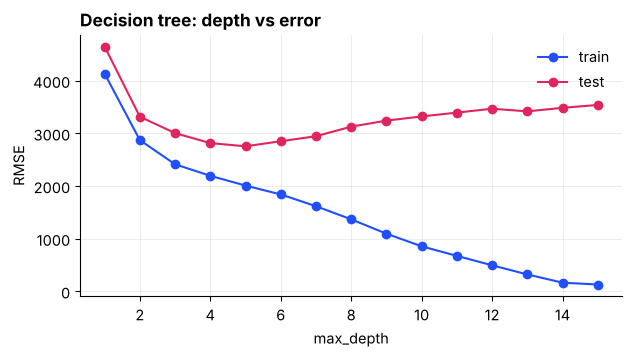

best test depth: 5


In [9]:
pre = ColumnTransformer([("num", StandardScaler(), ["age", "bmi", "children"]), ("cat", OneHotEncoder(drop="if_binary"), cat)])
cols = ["age", "bmi", "children"] + cat
plain = Pipeline([("pre", pre), ("m", Ridge())]).fit(Xtr[cols], ytr)
logged = TransformedTargetRegressor(regressor=Pipeline([("pre", pre), ("m", Ridge())]), func=np.log1p, inverse_func=np.expm1).fit(Xtr[cols], ytr)
print("Ex 1 RMSE plain:", round(root_mean_squared_error(yte, plain.predict(Xte[cols]))), "| log target:", round(root_mean_squared_error(yte, logged.predict(Xte[cols]))))
depths = range(1, 16)
tr_e, te_e = [], []
for dpt in depths:
    t = Pipeline([("pre", pre), ("m", DecisionTreeRegressor(max_depth=dpt, random_state=0))]).fit(Xtr[cols], ytr)
    tr_e.append(root_mean_squared_error(ytr, t.predict(Xtr[cols])))
    te_e.append(root_mean_squared_error(yte, t.predict(Xte[cols])))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(depths, tr_e, marker="o", label="train"); ax.plot(depths, te_e, marker="o", label="test")
ax.set(xlabel="max_depth", ylabel="RMSE", title="Decision tree: depth vs error"); ax.legend(); plt.show()
print("best test depth:", list(depths)[int(np.argmin(te_e))])

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>pre = ColumnTransformer([(&quot;num&quot;, StandardScaler(), [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;]), (&quot;cat&quot;, OneHotEncoder(drop=&quot;if_binary&quot;), cat)])</code></td><td>Shared preprocessing.</td></tr>
<tr><td><code>cols = [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;] + cat</code></td><td>Columns used.</td></tr>
<tr><td><code>plain = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, Ridge())]).fit(Xtr[cols], ytr)</code></td><td>Plain Ridge.</td></tr>
<tr><td><code>logged = TransformedTargetRegressor(regressor=Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, Ridge())]), func=np.log1p, inverse_func=np.expm1).fit(Xtr[cols], ytr)</code></td><td>Log target.</td></tr>
<tr><td><code>print(&quot;Ex 1 RMSE plain:&quot;, round(root_mean_squared_error(yte, plain.predict(Xte[cols]))), &quot;| log target:&quot;, round(root_mean_squared_error(yte, logged.predict(Xte[cols]))))</code></td><td>Compare.</td></tr>
<tr><td><code>depths = range(1, 16)</code></td><td>Depths to try.</td></tr>
<tr><td><code>tr_e, te_e = [], []</code></td><td>Errors.</td></tr>
<tr><td><code>for dpt in depths:</code></td><td>Each depth.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;t = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, DecisionTreeRegressor(max_depth=dpt, random_state=0))]).fit(Xtr[cols], ytr)</code></td><td>Fit a tree.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;tr_e.append(root_mean_squared_error(ytr, t.predict(Xtr[cols])))</code></td><td>Training RMSE.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;te_e.append(root_mean_squared_error(yte, t.predict(Xte[cols])))</code></td><td>Test RMSE.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(7, 3.4))</code></td><td>New figure.</td></tr>
<tr><td><code>ax.plot(depths, tr_e, marker=&quot;o&quot;, label=&quot;train&quot;); ax.plot(depths, te_e, marker=&quot;o&quot;, label=&quot;test&quot;)</code></td><td>Both curves.</td></tr>
<tr><td><code>ax.set(xlabel=&quot;max_depth&quot;, ylabel=&quot;RMSE&quot;, title=&quot;Decision tree: depth vs error&quot;); ax.legend(); plt.show()</code></td><td>Labels and draw.</td></tr>
<tr><td><code>print(&quot;best test depth:&quot;, list(depths)[int(np.argmin(te_e))])</code></td><td>Where test error is lowest.</td></tr>
</table>
</details>

## [Chapter 22](../notebooks/part-5-scikit-learn/22-sklearn-classification.ipynb): Classification

**Exercise 1: a 98%-recall threshold from cross-validated probabilities**

In [10]:
bc = load_breast_cancer()
Xb, yb = bc.data, 1 - bc.target
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=0)
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
oof = cross_val_predict(clf, Xtr, ytr, cv=5, method="predict_proba")[:, 1]
ths = np.linspace(0.01, 0.99, 99)
rec = np.array([recall_score(ytr, (oof >= t).astype(int)) for t in ths])
t98 = ths[rec >= 0.98].max()
p = (clf.fit(Xtr, ytr).predict_proba(Xte)[:, 1] >= t98).astype(int)
print(f"threshold={t98:.2f}  test recall={recall_score(yte, p):.3f}  test precision={precision_score(yte, p):.3f}")

threshold=0.10  test recall=1.000  test precision=0.828


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>bc = load_breast_cancer()</code></td><td>Data.</td></tr>
<tr><td><code>Xb, yb = bc.data, 1 - bc.target</code></td><td>1 = malignant, as in the chapter.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))</code></td><td>Model.</td></tr>
<tr><td><code>oof = cross_val_predict(clf, Xtr, ytr, cv=5, method=&quot;predict_proba&quot;)[:, 1]</code></td><td>Out-of-fold probabilities on training data.</td></tr>
<tr><td><code>ths = np.linspace(0.01, 0.99, 99)</code></td><td>Candidate thresholds.</td></tr>
<tr><td><code>rec = np.array([recall_score(ytr, (oof &gt;= t).astype(int)) for t in ths])</code></td><td>Training (OOF) recall at each.</td></tr>
<tr><td><code>t98 = ths[rec &gt;= 0.98].max()</code></td><td>Highest threshold still reaching 98% recall.</td></tr>
<tr><td><code>p = (clf.fit(Xtr, ytr).predict_proba(Xte)[:, 1] &gt;= t98).astype(int)</code></td><td>Apply it to the test set.</td></tr>
<tr><td><code>print(f&quot;threshold={t98:.2f}  test recall={recall_score(yte, p):.3f}  test precision={precision_score(yte, p):.3f}&quot;)</code></td><td>Report.</td></tr>
</table>
</details>

**Exercise 2: boosting with class weights**

In [11]:
Xi, yi = make_classification(n_samples=4000, n_features=20, n_informative=5, weights=[0.97, 0.03], flip_y=0.01, random_state=1)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, stratify=yi, test_size=0.3, random_state=1)
for cw in [None, "balanced"]:
    pr = HistGradientBoostingClassifier(class_weight=cw, random_state=0).fit(Xtr, ytr).predict(Xte)
    print(f"class_weight={cw}: recall={recall_score(yte, pr):.3f} precision={precision_score(yte, pr, zero_division=0):.3f} bal_acc={balanced_accuracy_score(yte, pr):.3f}")

class_weight=None: recall=0.300 precision=0.923 bal_acc=0.650


class_weight=balanced: recall=0.425 precision=0.810 bal_acc=0.711


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>Xi, yi = make_classification(n_samples=4000, n_features=20, n_informative=5, weights=[0.97, 0.03], flip_y=0.01, random_state=1)</code></td><td>Same data as the chapter.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xi, yi, stratify=yi, test_size=0.3, random_state=1)</code></td><td>Split.</td></tr>
<tr><td><code>for cw in [None, &quot;balanced&quot;]:</code></td><td>Without and with class weights.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;pr = HistGradientBoostingClassifier(class_weight=cw, random_state=0).fit(Xtr, ytr).predict(Xte)</code></td><td>Fit and predict.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;class_weight={cw}: recall={recall_score(yte, pr):.3f} precision={precision_score(yte, pr, zero_division=0):.3f} bal_acc={balanced_accuracy_score(yte, pr):.3f}&quot;)</code></td><td>Compare.</td></tr>
</table>
</details>

**Exercise 3: three ROC curves on one axes**

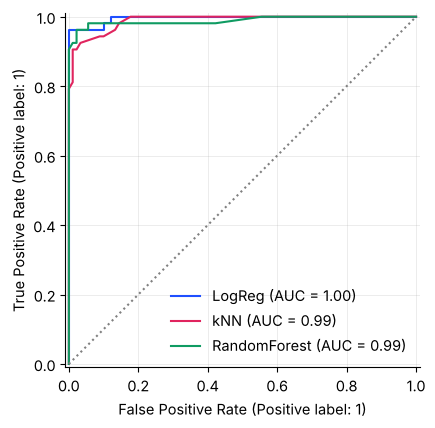

In [12]:
from sklearn.metrics import RocCurveDisplay
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=0)
fig, ax = plt.subplots(figsize=(5.5, 4.6))
for name, m in [("LogReg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
                ("kNN", make_pipeline(StandardScaler(), KNeighborsClassifier(15))),
                ("RandomForest", RandomForestClassifier(random_state=0))]:
    RocCurveDisplay.from_estimator(m.fit(Xtr, ytr), Xte, yte, name=name, ax=ax)
ax.plot([0, 1], [0, 1], ls=":", color="grey"); plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.metrics import RocCurveDisplay</code></td><td>ROC plotting.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.25, stratify=yb, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(5.5, 4.6))</code></td><td>One axes for all curves.</td></tr>
<tr><td><code>for name, m in [(&quot;LogReg&quot;, make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),</code></td><td>Three models...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;RocCurveDisplay.from_estimator(m.fit(Xtr, ytr), Xte, yte, name=name, ax=ax)</code></td><td>...each drawn on the same ax.</td></tr>
<tr><td><code>ax.plot([0, 1], [0, 1], ls=&quot;:&quot;, color=&quot;grey&quot;); plt.show()</code></td><td>Chance line and draw.</td></tr>
</table>
</details>

## [Chapter 23](../notebooks/part-5-scikit-learn/23-sklearn-model-selection.ipynb): Model selection

**Exercises 1-3: tune kNN, coefficient stability, 5- vs 10-fold**

In [13]:
gs = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                  {"kneighborsclassifier__n_neighbors": range(1, 31), "kneighborsclassifier__weights": ["uniform", "distance"]},
                  cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy", n_jobs=-1).fit(Xb, yb)
print("Ex 1:", gs.best_params_, round(gs.best_score_, 4))
res = cross_validate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xb, yb, cv=5, return_estimator=True)
coefs = np.array([e[-1].coef_[0] for e in res["estimator"]])
cv_ = pd.DataFrame({"mean": coefs.mean(0), "sd": coefs.std(0)}, index=bc.feature_names)
print("Ex 2 (most variable coefficients):\n", cv_.sort_values("sd", ascending=False).head(4).round(3))
for k in [5, 10]:
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xb, yb, cv=StratifiedKFold(k, shuffle=True, random_state=0))
    print(f"Ex 3: {k}-fold mean={s.mean():.4f} sd={s.std():.4f}")

Ex 1: {'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__weights': 'distance'} 0.9684
Ex 2 (most variable coefficients):
                           mean     sd
compactness error       -0.789  0.205
smoothness error         0.169  0.195
worst fractal dimension  0.427  0.161
symmetry error          -0.291  0.160
Ex 3: 5-fold mean=0.9789 sd=0.0142
Ex 3: 10-fold mean=0.9772 sd=0.0193


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>gs = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),</code></td><td>Scaled kNN...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;{&quot;kneighborsclassifier__n_neighbors&quot;: range(1, 31), &quot;kneighborsclassifier__weights&quot;: [&quot;uniform&quot;, &quot;distance&quot;]},</code></td><td>...60 combinations.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring=&quot;accuracy&quot;, n_jobs=-1).fit(Xb, yb)</code></td><td>Search.</td></tr>
<tr><td><code>print(&quot;Ex 1:&quot;, gs.best_params_, round(gs.best_score_, 4))</code></td><td>Best settings.</td></tr>
<tr><td><code>res = cross_validate(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xb, yb, cv=5, return_estimator=True)</code></td><td>Keep each fold&#x27;s fitted model.</td></tr>
<tr><td><code>coefs = np.array([e[-1].coef_[0] for e in res[&quot;estimator&quot;]])</code></td><td>e[-1] is the last pipeline step; one row per fold.</td></tr>
<tr><td><code>cv_ = pd.DataFrame({&quot;mean&quot;: coefs.mean(0), &quot;sd&quot;: coefs.std(0)}, index=bc.feature_names)</code></td><td>Mean and SD per feature.</td></tr>
<tr><td><code>print(&quot;Ex 2 (most variable coefficients):\n&quot;, cv_.sort_values(&quot;sd&quot;, ascending=False).head(4).round(3))</code></td><td>The least stable ones.</td></tr>
<tr><td><code>for k in [5, 10]:</code></td><td>Fold counts.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xb, yb, cv=StratifiedKFold(k, shuffle=True, random_state=0))</code></td><td>CV scores.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;Ex 3: {k}-fold mean={s.mean():.4f} sd={s.std():.4f}&quot;)</code></td><td>Similar means; 10-fold scores vary more (smaller test folds).</td></tr>
</table>
</details>

## [Chapter 24](../notebooks/part-5-scikit-learn/24-sklearn-unsupervised.ipynb): Unsupervised learning

**Exercise 1: customer segments**

In [14]:
from sklearn.cluster import KMeans
d = ins.dropna()[["age", "bmi", "charges"]]
labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(d))
prof = d.groupby(labels).mean().round(1)
prof["n"] = np.bincount(labels)
prof["smoker_share"] = ins.dropna().groupby(labels)["smoker"].apply(lambda s: (s == "yes").mean()).round(2)
print(prof)

    age   bmi  charges    n  smoker_share
0  52.9  29.5  20521.6  369          0.00
1  29.3  29.6  14272.1  411          0.00
2  41.6  29.4  40306.7  180          0.99


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.cluster import KMeans</code></td><td>k-means.</td></tr>
<tr><td><code>d = ins.dropna()[[&quot;age&quot;, &quot;bmi&quot;, &quot;charges&quot;]]</code></td><td>Three numeric features.</td></tr>
<tr><td><code>labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(d))</code></td><td>Cluster the scaled data.</td></tr>
<tr><td><code>prof = d.groupby(labels).mean().round(1)</code></td><td>Profile: mean of each feature per cluster.</td></tr>
<tr><td><code>prof[&quot;n&quot;] = np.bincount(labels)</code></td><td>Cluster sizes.</td></tr>
<tr><td><code>prof[&quot;smoker_share&quot;] = ins.dropna().groupby(labels)[&quot;smoker&quot;].apply(lambda s: (s == &quot;yes&quot;).mean()).round(2)</code></td><td>Who&#x27;s in each cluster?</td></tr>
<tr><td><code>print(prof)</code></td><td>One high-charge cluster that is mostly smokers.</td></tr>
</table>
</details>

**Exercises 2 and 3: PCA of wines; t-SNE perplexity**

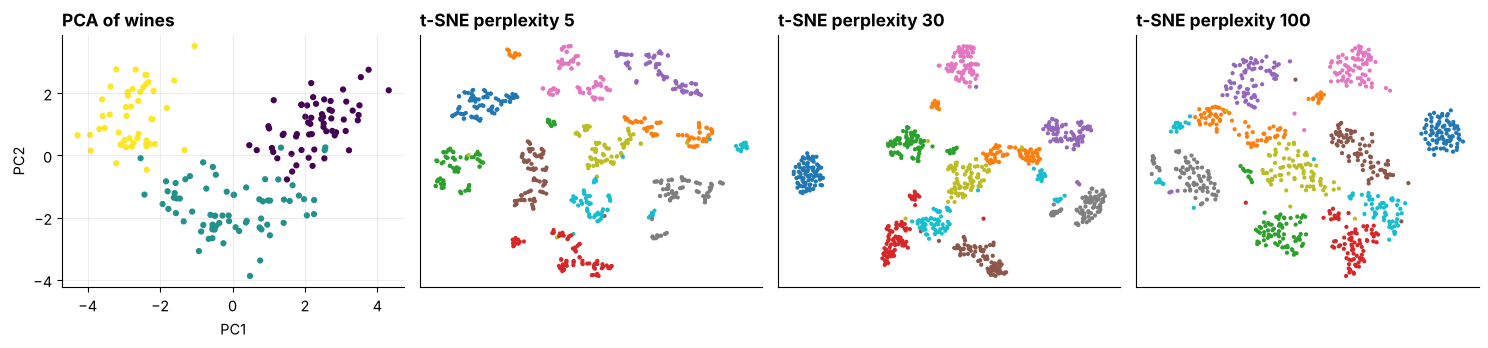

In [15]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
Z = make_pipeline(StandardScaler(), PCA(2)).fit_transform(Xw)
dg = load_digits()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
axes[0].scatter(Z[:, 0], Z[:, 1], c=yw, cmap="viridis", s=12); axes[0].set(title="PCA of wines", xlabel="PC1", ylabel="PC2")
for ax, perp in zip(axes[1:], [5, 30, 100]):
    emb = TSNE(perplexity=perp, init="pca", random_state=0).fit_transform(dg.data[:800])
    ax.scatter(emb[:, 0], emb[:, 1], c=dg.target[:800], cmap="tab10", s=4); ax.set(title=f"t-SNE perplexity {perp}", xticks=[], yticks=[])
plt.tight_layout(); plt.show()

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.decomposition import PCA</code></td><td>PCA.</td></tr>
<tr><td><code>from sklearn.manifold import TSNE</code></td><td>t-SNE.</td></tr>
<tr><td><code>Z = make_pipeline(StandardScaler(), PCA(2)).fit_transform(Xw)</code></td><td>Wine -&gt; 2 components.</td></tr>
<tr><td><code>dg = load_digits()</code></td><td>Digits.</td></tr>
<tr><td><code>fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))</code></td><td>Four panels.</td></tr>
<tr><td><code>axes[0].scatter(Z[:, 0], Z[:, 1], c=yw, cmap=&quot;viridis&quot;, s=12); axes[0].set(title=&quot;PCA of wines&quot;, xlabel=&quot;PC1&quot;, ylabel=&quot;PC2&quot;)</code></td><td>PCA panel.</td></tr>
<tr><td><code>for ax, perp in zip(axes[1:], [5, 30, 100]):</code></td><td>Three perplexities.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;emb = TSNE(perplexity=perp, init=&quot;pca&quot;, random_state=0).fit_transform(dg.data[:800])</code></td><td>800 digits keep it quick.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;ax.scatter(emb[:, 0], emb[:, 1], c=dg.target[:800], cmap=&quot;tab10&quot;, s=4); ax.set(title=f&quot;t-SNE perplexity {perp}&quot;, xticks=[], yticks=[])</code></td><td>Plot.</td></tr>
<tr><td><code>plt.tight_layout(); plt.show()</code></td><td>Draw.</td></tr>
</table>
</details>

## [Chapter 25](../notebooks/part-5-scikit-learn/25-sklearn-interpret.ipynb): Interpreting and saving models

**Exercises 1-3: MAE-based importance, ICE for children, save and reload**

Ex 1: {'smoker': 5553.0, 'age': 2572.0, 'bmi': 332.0, 'children': 88.0, 'sex': 9.0, 'region': -1.0}


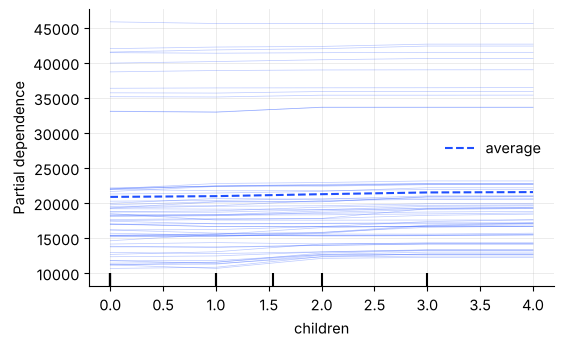

Ex 3 prediction: [14616.]


In [16]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import joblib
X = ins.drop(columns="charges").astype({"age": float, "children": float})
y = ins["charges"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)
pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), ["age", "bmi", "children"]),
                         ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), ["sex", "smoker", "region"])])
rf = Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=0, n_jobs=-1))]).fit(Xtr, ytr)
pi = permutation_importance(rf, Xte, yte, scoring="neg_mean_absolute_error", n_repeats=10, random_state=0, n_jobs=-1)
print("Ex 1:", pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).round(0).to_dict())
fig, ax = plt.subplots(figsize=(6, 3.6))
PartialDependenceDisplay.from_estimator(rf, Xte, ["children"], kind="both", subsample=60, random_state=0, ax=ax)
plt.show()
joblib.dump(rf, "rf.joblib")
reloaded = joblib.load("rf.joblib")
new = pd.DataFrame([{"age": 33.0, "sex": "male", "bmi": 27.5, "children": 1.0, "smoker": "no", "region": "northwest"}])
print("Ex 3 prediction:", reloaded.predict(new).round(0))

<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.inspection import permutation_importance, PartialDependenceDisplay</code></td><td>Interpretation tools.</td></tr>
<tr><td><code>import joblib</code></td><td>Saving models.</td></tr>
<tr><td><code>X = ins.drop(columns=&quot;charges&quot;).astype({&quot;age&quot;: float, &quot;children&quot;: float})</code></td><td>Floats for partial dependence.</td></tr>
<tr><td><code>y = ins[&quot;charges&quot;]</code></td><td>Target.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>pre = ColumnTransformer([(&quot;num&quot;, SimpleImputer(strategy=&quot;median&quot;), [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;]),</code></td><td>Impute numeric...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;(&quot;cat&quot;, OneHotEncoder(handle_unknown=&quot;ignore&quot;, drop=&quot;if_binary&quot;), [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;])])</code></td><td>...encode categorical.</td></tr>
<tr><td><code>rf = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=0, n_jobs=-1))]).fit(Xtr, ytr)</code></td><td>Fit.</td></tr>
<tr><td><code>pi = permutation_importance(rf, Xte, yte, scoring=&quot;neg_mean_absolute_error&quot;, n_repeats=10, random_state=0, n_jobs=-1)</code></td><td>MAE-based importance.</td></tr>
<tr><td><code>print(&quot;Ex 1:&quot;, pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).round(0).to_dict())</code></td><td>Same ranking as with R²: smoker, age, bmi...</td></tr>
<tr><td><code>fig, ax = plt.subplots(figsize=(6, 3.6))</code></td><td>New figure.</td></tr>
<tr><td><code>PartialDependenceDisplay.from_estimator(rf, Xte, [&quot;children&quot;], kind=&quot;both&quot;, subsample=60, random_state=0, ax=ax)</code></td><td>ICE + PDP.</td></tr>
<tr><td><code>plt.show()</code></td><td>Draw.</td></tr>
<tr><td><code>joblib.dump(rf, &quot;rf.joblib&quot;)</code></td><td>Save.</td></tr>
<tr><td><code>reloaded = joblib.load(&quot;rf.joblib&quot;)</code></td><td>In a new session you&#x27;d start here.</td></tr>
<tr><td><code>new = pd.DataFrame([{&quot;age&quot;: 33.0, &quot;sex&quot;: &quot;male&quot;, &quot;bmi&quot;: 27.5, &quot;children&quot;: 1.0, &quot;smoker&quot;: &quot;no&quot;, &quot;region&quot;: &quot;northwest&quot;}])</code></td><td>A new customer.</td></tr>
<tr><td><code>print(&quot;Ex 3 prediction:&quot;, reloaded.predict(new).round(0))</code></td><td>Works with raw input.</td></tr>
</table>
</details>

## [Chapter 26](../notebooks/part-6-tensorflow-keras/26-tf-basics.ipynb): TensorFlow fundamentals

**Exercises 1-3: minimise a function, two features, a tf.data pipeline**

In [17]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
x = tf.Variable(0.0)
for _ in range(100):
    with tf.GradientTape() as tape:
        f = (x - 4.0) ** 2 + 1.0
    x.assign_sub(0.1 * tape.gradient(f, x))
print("Ex 1: x =", round(float(x), 4), " f(x) =", round(float((x - 4) ** 2 + 1), 4))
rng = np.random.default_rng(0)
X2 = rng.uniform(-1, 1, (300, 2)).astype("float32")
y2 = (1.5 * X2[:, 0] - 2.0 * X2[:, 1] + 0.5).astype("float32")
W, b = tf.Variable(tf.zeros(2)), tf.Variable(0.0)
opt = tf.keras.optimizers.SGD(0.2)
for _ in range(300):
    with tf.GradientTape() as tape:
        loss = tf.reduce_mean((tf.linalg.matvec(X2, W) + b - y2) ** 2)
    opt.apply_gradients(zip(tape.gradient(loss, [W, b]), [W, b]))
print("Ex 2: W =", W.numpy().round(3), " b =", round(float(b), 3))
Xb32 = StandardScaler().fit_transform(load_breast_cancer().data).astype("float32")
ds = tf.data.Dataset.from_tensor_slices((Xb32, load_breast_cancer().target)).shuffle(569, seed=0).batch(64)
print("Ex 3:", [tuple(xb.shape) for xb, _ in ds.take(2)], "batches:", len(list(ds)))

I0000 00:00:1795699389.780630   26763 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795699391.037816   26763 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Ex 1: x = 4.0  f(x) = 1.0


Ex 2: W = [ 1.5 -2. ]  b = 0.5
Ex 3: [(64, 30), (64, 30)] batches: 9


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>import os</code></td><td>Environment variables.</td></tr>
<tr><td><code>os.environ[&quot;TF_CPP_MIN_LOG_LEVEL&quot;] = &quot;3&quot;</code></td><td>Quiet TensorFlow.</td></tr>
<tr><td><code>import tensorflow as tf</code></td><td>TensorFlow.</td></tr>
<tr><td><code>x = tf.Variable(0.0)</code></td><td>Start at 0.</td></tr>
<tr><td><code>for _ in range(100):</code></td><td>100 steps.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;f = (x - 4.0) ** 2 + 1.0</code></td><td>The function.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;x.assign_sub(0.1 * tape.gradient(f, x))</code></td><td>x -= 0.1 * df/dx.</td></tr>
<tr><td><code>print(&quot;Ex 1: x =&quot;, round(float(x), 4), &quot; f(x) =&quot;, round(float((x - 4) ** 2 + 1), 4))</code></td><td>Converges to x = 4, f = 1.</td></tr>
<tr><td><code>rng = np.random.default_rng(0)</code></td><td>Data for exercise 2.</td></tr>
<tr><td><code>X2 = rng.uniform(-1, 1, (300, 2)).astype(&quot;float32&quot;)</code></td><td>Two features.</td></tr>
<tr><td><code>y2 = (1.5 * X2[:, 0] - 2.0 * X2[:, 1] + 0.5).astype(&quot;float32&quot;)</code></td><td>True weights 1.5, -2.0; intercept 0.5.</td></tr>
<tr><td><code>W, b = tf.Variable(tf.zeros(2)), tf.Variable(0.0)</code></td><td>Two weights and a bias.</td></tr>
<tr><td><code>opt = tf.keras.optimizers.SGD(0.2)</code></td><td>Optimiser.</td></tr>
<tr><td><code>for _ in range(300):</code></td><td>Training steps.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;loss = tf.reduce_mean((tf.linalg.matvec(X2, W) + b - y2) ** 2)</code></td><td>matvec computes X2 @ W.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;opt.apply_gradients(zip(tape.gradient(loss, [W, b]), [W, b]))</code></td><td>Update.</td></tr>
<tr><td><code>print(&quot;Ex 2: W =&quot;, W.numpy().round(3), &quot; b =&quot;, round(float(b), 3))</code></td><td>Recovers the true values.</td></tr>
<tr><td><code>Xb32 = StandardScaler().fit_transform(load_breast_cancer().data).astype(&quot;float32&quot;)</code></td><td>Scaled features.</td></tr>
<tr><td><code>ds = tf.data.Dataset.from_tensor_slices((Xb32, load_breast_cancer().target)).shuffle(569, seed=0).batch(64)</code></td><td>Shuffled batches of 64.</td></tr>
<tr><td><code>print(&quot;Ex 3:&quot;, [tuple(xb.shape) for xb, _ in ds.take(2)], &quot;batches:&quot;, len(list(ds)))</code></td><td>(64, 30) batches; ceil(569/64) = 9.</td></tr>
</table>
</details>

## [Chapter 27](../notebooks/part-6-tensorflow-keras/27-keras-mlp.ipynb): Neural networks with Keras

**Exercises 1-3: width, batch normalisation, five seeds**

In [18]:
from tensorflow import keras
from tensorflow.keras import layers
Xtr, Xte, ytr, yte = train_test_split(load_breast_cancer().data, load_breast_cancer().target, test_size=0.2, stratify=load_breast_cancer().target, random_state=0)
sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr).astype("float32"), sc.transform(Xte).astype("float32")
def mlp(hidden, bn=False, seed=0):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([keras.Input(shape=(30,))])
    for u in hidden:
        m.add(layers.Dense(u, activation="relu"))
        if bn: m.add(layers.BatchNormalization())
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    m.fit(Xtr, ytr, epochs=60, batch_size=32, verbose=0, validation_split=0.15,
          callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    return m.evaluate(Xte, yte, verbose=0)[1]
for h in [[8], [256], [32, 16]]:
    print("Ex 1 hidden", h, "acc", round(mlp(h), 4))
print("Ex 2 with BatchNorm:", round(mlp([32, 16], bn=True), 4))
accs = [mlp([32, 16], seed=s) for s in range(5)]
print(f"Ex 3: {np.mean(accs):.4f} ± {np.std(accs):.4f}")

Ex 1 hidden [8] acc 0.9561


Ex 1 hidden [256] acc 0.9561


Ex 1 hidden [32, 16] acc 0.9737


Ex 2 with BatchNorm: 0.9649


Ex 3: 0.9596 ± 0.0070


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from tensorflow import keras</code></td><td>Keras.</td></tr>
<tr><td><code>from tensorflow.keras import layers</code></td><td>Layers.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(load_breast_cancer().data, load_breast_cancer().target, test_size=0.2, stratify=load_breast_cancer().target, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr).astype(&quot;float32&quot;), sc.transform(Xte).astype(&quot;float32&quot;)</code></td><td>Scale.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;keras.utils.set_random_seed(seed)</code></td><td>Reproducible.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m = keras.Sequential([keras.Input(shape=(30,))])</code></td><td>Input layer.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;for u in hidden:</code></td><td>Hidden layers.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;m.add(layers.Dense(u, activation=&quot;relu&quot;))</code></td><td>Dense layer.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;if bn: m.add(layers.BatchNormalization())</code></td><td>Optional batch normalisation.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m.add(layers.Dense(1, activation=&quot;sigmoid&quot;))</code></td><td>Output.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m.compile(optimizer=&quot;adam&quot;, loss=&quot;binary_crossentropy&quot;, metrics=[&quot;accuracy&quot;])</code></td><td>Compile.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m.fit(Xtr, ytr, epochs=60, batch_size=32, verbose=0, validation_split=0.15,</code></td><td>Train...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])</code></td><td>...with early stopping.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return m.evaluate(Xte, yte, verbose=0)[1]</code></td><td>Test accuracy.</td></tr>
<tr><td><code>for h in [[8], [256], [32, 16]]:</code></td><td>Exercise 1: different widths.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(&quot;Ex 1 hidden&quot;, h, &quot;acc&quot;, round(mlp(h), 4))</code></td><td>All similar: this problem is easy.</td></tr>
<tr><td><code>print(&quot;Ex 2 with BatchNorm:&quot;, round(mlp([32, 16], bn=True), 4))</code></td><td>Similar accuracy; BN mainly speeds up training of deeper nets.</td></tr>
<tr><td><code>accs = [mlp([32, 16], seed=s) for s in range(5)]</code></td><td>Exercise 3: five seeds.</td></tr>
<tr><td><code>print(f&quot;Ex 3: {np.mean(accs):.4f} ± {np.std(accs):.4f}&quot;)</code></td><td>Report mean ± SD.</td></tr>
</table>
</details>

## [Chapter 28](../notebooks/part-6-tensorflow-keras/28-keras-advanced.ipynb): CNNs and sequence models

**Exercise 1: augmentation in the CNN**

In [19]:
dg = load_digits()
Xd = (dg.images / 16.0).astype("float32")[..., None]
Xtr, Xte, ytr, yte = train_test_split(Xd, dg.target, test_size=0.2, stratify=dg.target, random_state=0)
def cnn(augment):
    keras.utils.set_random_seed(0)
    aug = [layers.RandomRotation(0.05), layers.RandomTranslation(0.1, 0.1)] if augment else []
    m = keras.Sequential([keras.Input(shape=(8, 8, 1)), *aug,
                          layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
                          layers.Conv2D(64, 3, padding="same", activation="relu"), layers.MaxPooling2D(),
                          layers.Flatten(), layers.Dense(64, activation="relu"), layers.Dense(10, activation="softmax")])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(Xtr, ytr, epochs=30, batch_size=64, verbose=0, validation_split=0.15,
          callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    return m.evaluate(Xte, yte, verbose=0)[1]
print("without augmentation:", round(cnn(False), 4), "| with:", round(cnn(True), 4))

without augmentation: 0.9667 | with: 0.9556


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>dg = load_digits()</code></td><td>Digits.</td></tr>
<tr><td><code>Xd = (dg.images / 16.0).astype(&quot;float32&quot;)[..., None]</code></td><td>(1797, 8, 8, 1).</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xd, dg.target, test_size=0.2, stratify=dg.target, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;keras.utils.set_random_seed(0)</code></td><td>Reproducible.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;aug = [layers.RandomRotation(0.05), layers.RandomTranslation(0.1, 0.1)] if augment else []</code></td><td>Optional augmentation layers.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m = keras.Sequential([keras.Input(shape=(8, 8, 1)), *aug,</code></td><td>Augmentation goes first; active only during training.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;layers.Flatten(), layers.Dense(64, activation=&quot;relu&quot;), layers.Dense(10, activation=&quot;softmax&quot;)])</code></td><td>The chapter&#x27;s CNN.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m.compile(optimizer=&quot;adam&quot;, loss=&quot;sparse_categorical_crossentropy&quot;, metrics=[&quot;accuracy&quot;])</code></td><td>Compile.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])</code></td><td>Train.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return m.evaluate(Xte, yte, verbose=0)[1]</code></td><td>Test accuracy.</td></tr>
<tr><td><code>print(&quot;without augmentation:&quot;, round(cnn(False), 4), &quot;| with:&quot;, round(cnn(True), 4))</code></td><td>On tiny 8x8 images the gain is small; on real photos it is often large.</td></tr>
</table>
</details>

**Exercises 2 and 3: GRU, window length, multi-step forecasts**

In [20]:
t = np.arange(1200, dtype="float32")
series = (np.sin(2 * np.pi * t / 50) + 0.5 * np.sin(2 * np.pi * t / 17) + 0.001 * t + np.random.default_rng(0).normal(0, 0.15, t.size)).astype("float32")
mu, sd_ = series[:1000].mean(), series[:1000].std(); s = (series - mu) / sd_
def windows(arr, w, h):
    X = np.stack([arr[i:i + w] for i in range(len(arr) - w - h + 1)])
    Y = np.stack([arr[i + w:i + w + h] for i in range(len(arr) - w - h + 1)])
    return X, Y
for w, h, cell in [(10, 1, "GRU"), (40, 1, "GRU"), (80, 1, "GRU"), (40, 5, "GRU")]:
    Xa, Ya = windows(s[:1000], w, h); Xb_, Yb_ = windows(s[1000 - w:], w, h)
    keras.utils.set_random_seed(0)
    m = keras.Sequential([keras.Input(shape=(w,)), layers.Reshape((w, 1)), layers.GRU(32), layers.Dense(h)])
    m.compile(optimizer="adam", loss="mse"); m.fit(Xa, Ya, epochs=20, batch_size=32, verbose=0)
    rmse = np.sqrt(np.mean((m.predict(Xb_, verbose=0) - Yb_) ** 2, axis=0)) * sd_
    print(f"{cell} window={w:<3} horizon={h}: test RMSE per step = {rmse.round(3)}")

GRU window=10  horizon=1: test RMSE per step = [0.228]


GRU window=40  horizon=1: test RMSE per step = [0.219]


GRU window=80  horizon=1: test RMSE per step = [0.218]


GRU window=40  horizon=5: test RMSE per step = [0.233 0.283 0.307 0.372 0.409]


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>t = np.arange(1200, dtype=&quot;float32&quot;)</code></td><td>Same series as the chapter.</td></tr>
<tr><td><code>mu, sd_ = series[:1000].mean(), series[:1000].std(); s = (series - mu) / sd_</code></td><td>Normalise with training statistics.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;X = np.stack([arr[i:i + w] for i in range(len(arr) - w - h + 1)])</code></td><td>Input windows.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;Y = np.stack([arr[i + w:i + w + h] for i in range(len(arr) - w - h + 1)])</code></td><td>The next h values.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;return X, Y</code></td><td>Arrays.</td></tr>
<tr><td><code>for w, h, cell in [(10, 1, &quot;GRU&quot;), (40, 1, &quot;GRU&quot;), (80, 1, &quot;GRU&quot;), (40, 5, &quot;GRU&quot;)]:</code></td><td>Exercise 2 (windows) and 3 (h = 5).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;Xa, Ya = windows(s[:1000], w, h); Xb_, Yb_ = windows(s[1000 - w:], w, h)</code></td><td>Train and test windows (chronological).</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;keras.utils.set_random_seed(0)</code></td><td>Reproducible.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m = keras.Sequential([keras.Input(shape=(w,)), layers.Reshape((w, 1)), layers.GRU(32), layers.Dense(h)])</code></td><td>GRU, h outputs.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;m.compile(optimizer=&quot;adam&quot;, loss=&quot;mse&quot;); m.fit(Xa, Ya, epochs=20, batch_size=32, verbose=0)</code></td><td>Train.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;rmse = np.sqrt(np.mean((m.predict(Xb_, verbose=0) - Yb_) ** 2, axis=0)) * sd_</code></td><td>RMSE per forecast step, original units.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;{cell} window={w:&lt;3} horizon={h}: test RMSE per step = {rmse.round(3)}&quot;)</code></td><td>For h = 5, error grows with the horizon.</td></tr>
</table>
</details>

## [Chapter 29](../notebooks/part-7-ml-for-research/29-research-protocol.ipynb): The research protocol

**Exercises 1 and 2: boosting as the primary model; nested CV instead of a test set**

In [21]:
bc = load_breast_cancer(); Xb, yb = bc.data, 1 - bc.target
outer = StratifiedKFold(5, shuffle=True, random_state=2026)
inner = StratifiedKFold(5, shuffle=True, random_state=1)
hgb = GridSearchCV(HistGradientBoostingClassifier(random_state=0),
                   {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31]}, cv=inner, scoring="roc_auc", n_jobs=-1)
lr = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver="liblinear")),
                  {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=inner, scoring="roc_auc", n_jobs=-1)
for name, est in [("HistGB", hgb), ("LogReg", lr)]:
    sc_ = cross_val_score(est, Xb, yb, cv=outer, scoring="roc_auc")
    print(f"{name}: nested CV ROC AUC = {sc_.mean():.4f} ± {sc_.std():.4f}")

HistGB: nested CV ROC AUC = 0.9927 ± 0.0053


LogReg: nested CV ROC AUC = 0.9951 ± 0.0051


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>bc = load_breast_cancer(); Xb, yb = bc.data, 1 - bc.target</code></td><td>Data, 1 = malignant.</td></tr>
<tr><td><code>outer = StratifiedKFold(5, shuffle=True, random_state=2026)</code></td><td>Outer loop: evaluation.</td></tr>
<tr><td><code>inner = StratifiedKFold(5, shuffle=True, random_state=1)</code></td><td>Inner loop: tuning.</td></tr>
<tr><td><code>hgb = GridSearchCV(HistGradientBoostingClassifier(random_state=0),</code></td><td>Tuned boosting...</td></tr>
<tr><td><code>lr = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, solver=&quot;liblinear&quot;)),</code></td><td>...vs tuned logistic regression.</td></tr>
<tr><td><code>for name, est in [(&quot;HistGB&quot;, hgb), (&quot;LogReg&quot;, lr)]:</code></td><td>Nested CV for each.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;sc_ = cross_val_score(est, Xb, yb, cv=outer, scoring=&quot;roc_auc&quot;)</code></td><td>Each outer fold runs a full grid search.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;{name}: nested CV ROC AUC = {sc_.mean():.4f} ± {sc_.std():.4f}&quot;)</code></td><td>Unbiased estimates.</td></tr>
</table>
</details>

Both models land within about one standard deviation of each other, so the conclusion doesn't change: the simpler, interpretable logistic regression is a defensible choice. Nested CV uses all 569 cases for evaluation, which gives a tighter estimate than a single 143-case test set.

**Exercise 3 (Methods paragraph).** A model answer, filled from the [Chapter 29](../notebooks/part-7-ml-for-research/29-research-protocol.ipynb) run: *"We used the Wisconsin Diagnostic Breast Cancer dataset (569 masses, 30 features; 37% malignant). Data were split, stratified by outcome, into training (n = 426) and test (n = 143) sets (seed 2026). Six candidate pipelines (dummy, logistic regression, kNN, RBF-SVM, random forest, histogram gradient boosting) were compared by 5 × 5 repeated stratified cross-validation on the training set, using ROC AUC as the primary metric. All preprocessing (standardisation) was embedded in scikit-learn pipelines. L1/L2-regularised logistic regression was tuned by grid search over C ∈ [10⁻³, 10²]. The decision threshold was fixed on out-of-fold training predictions to target ≥ 95% sensitivity. The final model was evaluated once on the test set; 95% confidence intervals were obtained from 2,000 bootstrap resamples. Analyses used Python 3.13 and scikit-learn 1.9."*

## [Chapter 30](../notebooks/part-7-ml-for-research/30-research-choosing.ipynb): Comparing models

**Exercises 1-3: corrected t-test on wines, bootstrap PR AUC, false-positive simulation**

In [22]:
from scipy import stats
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score
def corrected_ttest(a, b, n_train, n_test):
    d = a - b; var = d.var(ddof=1) * (1 / len(d) + n_test / n_train)
    t = d.mean() / np.sqrt(var); return d.mean(), 2 * stats.t.sf(abs(t), len(d) - 1)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=0)
a = cross_val_score(make_pipeline(StandardScaler(), SVC()), Xw, yw, cv=cv)
b = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xw, yw, cv=cv)
diff, p = corrected_ttest(a, b, int(len(yw) * 0.9), len(yw) - int(len(yw) * 0.9))
print(f"Ex 1: SVC - LogReg = {diff:+.4f}, corrected p = {p:.3f}")
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.3, stratify=yb, random_state=1)
pa = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
pb = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
rng = np.random.default_rng(0); diffs = []
for _ in range(2000):
    i = rng.integers(0, len(yte), len(yte))
    if yte[i].min() != yte[i].max():
        diffs.append(average_precision_score(yte[i], pa[i]) - average_precision_score(yte[i], pb[i]))
print("Ex 2: PR AUC difference 95% CI:", np.percentile(diffs, [2.5, 97.5]).round(4))
hits = 0
for rep in range(200):
    s1 = 0.85 + rng.normal(0, 0.02, 10)
    s2 = s1 + rng.normal(0, 0.01, 10)
    hits += stats.ttest_rel(s1, s2).pvalue < 0.05
print(f"Ex 3: naive test 'significant' in {hits / 2:.1f}% of 200 null comparisons")

Ex 1: SVC - LogReg = -0.0001, corrected p = 0.992


Ex 2: PR AUC difference 95% CI: [-0.0083  0.0095]
Ex 3: naive test 'significant' in 5.5% of 200 null comparisons


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from scipy import stats</code></td><td>Statistics.</td></tr>
<tr><td><code>from sklearn.model_selection import RepeatedStratifiedKFold</code></td><td>Repeated CV.</td></tr>
<tr><td><code>from sklearn.svm import SVC</code></td><td>SVM.</td></tr>
<tr><td><code>from sklearn.metrics import average_precision_score</code></td><td>PR AUC.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;d = a - b; var = d.var(ddof=1) * (1 / len(d) + n_test / n_train)</code></td><td>Nadeau-Bengio variance.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;t = d.mean() / np.sqrt(var); return d.mean(), 2 * stats.t.sf(abs(t), len(d) - 1)</code></td><td>Difference and p-value.</td></tr>
<tr><td><code>cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=0)</code></td><td>50 shared splits.</td></tr>
<tr><td><code>a = cross_val_score(make_pipeline(StandardScaler(), SVC()), Xw, yw, cv=cv)</code></td><td>SVM accuracy.</td></tr>
<tr><td><code>b = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Xw, yw, cv=cv)</code></td><td>LogReg accuracy.</td></tr>
<tr><td><code>diff, p = corrected_ttest(a, b, int(len(yw) * 0.9), len(yw) - int(len(yw) * 0.9))</code></td><td>10-fold sizes.</td></tr>
<tr><td><code>print(f&quot;Ex 1: SVC - LogReg = {diff:+.4f}, corrected p = {p:.3f}&quot;)</code></td><td>No evidence of a difference.</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.3, stratify=yb, random_state=1)</code></td><td>Breast-cancer split.</td></tr>
<tr><td><code>pa = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr).predict_proba(Xte)[:, 1]</code></td><td>Model A.</td></tr>
<tr><td><code>pb = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(Xtr, ytr).predict_proba(Xte)[:, 1]</code></td><td>Model B.</td></tr>
<tr><td><code>rng = np.random.default_rng(0); diffs = []</code></td><td>Bootstrap.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;i = rng.integers(0, len(yte), len(yte))</code></td><td>Resample test cases.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;if yte[i].min() != yte[i].max():</code></td><td>Need both classes.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;diffs.append(average_precision_score(yte[i], pa[i]) - average_precision_score(yte[i], pb[i]))</code></td><td>Paired difference.</td></tr>
<tr><td><code>print(&quot;Ex 2: PR AUC difference 95% CI:&quot;, np.percentile(diffs, [2.5, 97.5]).round(4))</code></td><td>Includes 0?</td></tr>
<tr><td><code>hits = 0</code></td><td>Exercise 3: simulation.</td></tr>
<tr><td><code>for rep in range(200):</code></td><td>200 simulated comparisons.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;s1 = 0.85 + rng.normal(0, 0.02, 10)</code></td><td>Model 1: 10 scores around a true accuracy of 0.85.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;s2 = s1 + rng.normal(0, 0.01, 10)</code></td><td>Model 2: the same true accuracy; independent small differences.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;hits += stats.ttest_rel(s1, s2).pvalue &lt; 0.05</code></td><td>Naive paired test.</td></tr>
<tr><td><code>print(f&quot;Ex 3: naive test &#x27;significant&#x27; in {hits / 2:.1f}% of 200 null comparisons&quot;)</code></td><td>Close to the nominal 5% in this simple setting.</td></tr>
</table>
</details>

In this simple simulation the scores are independent across splits, so the naive test happens to behave. Real CV scores share training data across folds, which makes their differences correlated; that is what makes the naive test overconfident in [Chapter 30](../notebooks/part-7-ml-for-research/30-research-choosing.ipynb) (p ≈ 0.0003 naive vs 0.28 corrected).

## [Chapter 31](../notebooks/part-7-ml-for-research/31-research-reporting.ipynb): Reproducibility and reporting

**Exercise 2: permutation test for the insurance regression**

In [23]:
from sklearn.model_selection import permutation_test_score
d = ins.dropna()
pre = ColumnTransformer([("num", StandardScaler(), ["age", "bmi", "children"]), ("cat", OneHotEncoder(drop="if_binary"), ["sex", "smoker", "region"])])
score, perm, p = permutation_test_score(Pipeline([("pre", pre), ("m", Ridge())]), d.drop(columns="charges"), d["charges"],
                                        scoring="r2", cv=5, n_permutations=50, random_state=0, n_jobs=-1)
print(f"real R2={score:.3f} | shuffled R2 mean={perm.mean():.3f} | p={p:.3f}")

real R2=0.952 | shuffled R2 mean=-0.016 | p=0.020


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.model_selection import permutation_test_score</code></td><td>Label-shuffling test.</td></tr>
<tr><td><code>d = ins.dropna()</code></td><td>Complete rows.</td></tr>
<tr><td><code>pre = ColumnTransformer([(&quot;num&quot;, StandardScaler(), [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;]), (&quot;cat&quot;, OneHotEncoder(drop=&quot;if_binary&quot;), [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;])])</code></td><td>Preprocessing.</td></tr>
<tr><td><code>score, perm, p = permutation_test_score(Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, Ridge())]), d.drop(columns=&quot;charges&quot;), d[&quot;charges&quot;],</code></td><td>Pipeline, X, y...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;scoring=&quot;r2&quot;, cv=5, n_permutations=50, random_state=0, n_jobs=-1)</code></td><td>...50 shuffles.</td></tr>
<tr><td><code>print(f&quot;real R2={score:.3f} | shuffled R2 mean={perm.mean():.3f} | p={p:.3f}&quot;)</code></td><td>Shuffled scores sit near 0 (slightly negative): no leakage.</td></tr>
</table>
</details>

**Exercise 1** is the `run_experiment.py` pattern from [Chapter 31](../notebooks/part-7-ml-for-research/31-research-reporting.ipynb) with the [Chapter 29](../notebooks/part-7-ml-for-research/29-research-protocol.ipynb) steps inside `main()`: put the seed, CV settings, candidate models and grid in the config, and write the metrics JSON, the fitted model and the figures into `results/run_<date>/`. **Exercise 3** is personal: every item you cannot fill in yet is a task for your project plan.

## [Chapter 32](../notebooks/part-8-debugging/32-debug-strategy.ipynb): How to debug

**Exercise 1.** In Jupyter, run `df.groupby("Region")["charges"].mean()` on the insurance data (note the capital R). After the `KeyError`, run `%debug` in a new cell; at the `(Pdb)` prompt type `u` until you reach your own frame, then `p df.columns.tolist()` to see the real name, `region`. Type `q` to quit. In a script, run `python -m pdb script.py`, type `c` to run until the crash, and inspect the same way.

**Exercise 2.** A good minimal reproducible example: a few lines of fake data built in the code (no files), only the imports needed, the single failing call, the full error message, and your versions (`python -c "import sklearn; print(sklearn.__version__)"`).

**Exercise 3.** Copy the `validate()` function from [Chapter 32](../notebooks/part-8-debugging/32-debug-strategy.ipynb), edit the `expected` schema to match your columns and dtypes, add range checks for your variables, and call it immediately after every `pd.read_csv`.

## [Chapter 33](../notebooks/part-8-debugging/33-debug-encyclopedia.ipynb): The error encyclopedia

**Three errors caused on purpose, then fixed**

In [24]:
from sklearn.linear_model import LinearRegression
df = pd.DataFrame({"x": [1.0, 2.0, 3.0], "y": [2.0, 4.1, 5.9]})
try:
    LinearRegression().fit(df["x"], df["y"])
except ValueError as e:
    print("caused:", str(e).split("\n")[0])
print("fixed :", LinearRegression().fit(df[["x"]], df["y"]).coef_.round(3))
try:
    np.ones((100, 3)) * np.ones(100)
except ValueError as e:
    print("caused:", e)
print("fixed :", (np.ones((100, 3)) * np.ones(100)[:, None]).shape)
try:
    {"lr": 0.01}["batch_size"]
except KeyError as e:
    print("caused: KeyError", e)
print("fixed :", {"lr": 0.01}.get("batch_size", 32))

caused: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.
fixed : [1.95]
caused: operands could not be broadcast together with shapes (100,3) (100,) 
fixed : (100, 3)
caused: KeyError 'batch_size'
fixed : 32


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>from sklearn.linear_model import LinearRegression</code></td><td>For error 1.</td></tr>
<tr><td><code>df = pd.DataFrame({&quot;x&quot;: [1.0, 2.0, 3.0], &quot;y&quot;: [2.0, 4.1, 5.9]})</code></td><td>Tiny data.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;LinearRegression().fit(df[&quot;x&quot;], df[&quot;y&quot;])</code></td><td>Error 1: 1-D X.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(&quot;caused:&quot;, str(e).split(&quot;\n&quot;)[0])</code></td><td>First line of the message.</td></tr>
<tr><td><code>print(&quot;fixed :&quot;, LinearRegression().fit(df[[&quot;x&quot;]], df[&quot;y&quot;]).coef_.round(3))</code></td><td>Double brackets give a 2-D X.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;np.ones((100, 3)) * np.ones(100)</code></td><td>Error 2: broadcasting.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(&quot;caused:&quot;, e)</code></td><td>The message.</td></tr>
<tr><td><code>print(&quot;fixed :&quot;, (np.ones((100, 3)) * np.ones(100)[:, None]).shape)</code></td><td>A column vector broadcasts.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;{&quot;lr&quot;: 0.01}[&quot;batch_size&quot;]</code></td><td>Error 3: KeyError.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;print(&quot;caused: KeyError&quot;, e)</code></td><td>The missing key.</td></tr>
<tr><td><code>print(&quot;fixed :&quot;, {&quot;lr&quot;: 0.01}.get(&quot;batch_size&quot;, 32))</code></td><td>A default instead of a crash.</td></tr>
</table>
</details>

## [Chapter 34](../notebooks/part-8-debugging/34-debug-models.ipynb): When the model is wrong

**Exercises 1 and 2: breaking the sanity check; a deliberate leak**

In [25]:
keras.utils.set_random_seed(0)
Xs, ys = (load_digits().data[:32] / 16).astype("float32"), load_digits().target[:32]
for lr_, loss in [(1e-2, "sparse_categorical_crossentropy"), (1e-6, "sparse_categorical_crossentropy"), (1e-2, "mse")]:
    net = keras.Sequential([keras.Input(shape=(64,)), layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])
    net.compile(optimizer=keras.optimizers.Adam(lr_), loss=loss, metrics=["accuracy"])
    try:
        acc = net.fit(Xs, ys, epochs=150, verbose=0).history["accuracy"][-1]
        print(f"lr={lr_:g} loss={loss:<32} train acc on 32 samples = {acc:.3f}")
    except ValueError as e:
        print(f"lr={lr_:g} loss={loss:<32} fails:", str(e).split(" for ")[0])
d = ins.dropna().copy()
d["leak"] = d["charges"] + np.random.default_rng(0).normal(0, 500, len(d))
Xtr, Xte, ytr, yte = train_test_split(d.drop(columns="charges"), d["charges"], test_size=0.25, random_state=0)
pre = ColumnTransformer([("num", "passthrough", ["age", "bmi", "children", "leak"]), ("cat", OneHotEncoder(drop="if_binary"), ["sex", "smoker", "region"])])
rf = Pipeline([("pre", pre), ("m", RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1))]).fit(Xtr, ytr)
pi = permutation_importance(rf, Xte, yte, n_repeats=5, random_state=0, n_jobs=-1)
print("test R2 with leak:", round(rf.score(Xte, yte), 4))
print(pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).round(3).head(3).to_dict())

lr=0.01 loss=sparse_categorical_crossentropy  train acc on 32 samples = 1.000


lr=1e-06 loss=sparse_categorical_crossentropy  train acc on 32 samples = 0.062
lr=0.01 loss=mse                              fails: Dimensions must be equal, but are 32 and 10


test R2 with leak: 0.997
{'leak': 2.012, 'age': 0.0, 'smoker': 0.0}


<details open><summary><b>What each line does</b></summary>

<table>
<tr><td><code>keras.utils.set_random_seed(0)</code></td><td>Reproducible.</td></tr>
<tr><td><code>Xs, ys = (load_digits().data[:32] / 16).astype(&quot;float32&quot;), load_digits().target[:32]</code></td><td>32 samples.</td></tr>
<tr><td><code>for lr_, loss in [(1e-2, &quot;sparse_categorical_crossentropy&quot;), (1e-6, &quot;sparse_categorical_crossentropy&quot;), (1e-2, &quot;mse&quot;)]:</code></td><td>Correct; tiny learning rate; wrong loss.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;net = keras.Sequential([keras.Input(shape=(64,)), layers.Dense(128, activation=&quot;relu&quot;), layers.Dense(10, activation=&quot;softmax&quot;)])</code></td><td>Same network.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;net.compile(optimizer=keras.optimizers.Adam(lr_), loss=loss, metrics=[&quot;accuracy&quot;])</code></td><td>Vary LR and loss.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;acc = net.fit(Xs, ys, epochs=150, verbose=0).history[&quot;accuracy&quot;][-1]</code></td><td>Final training accuracy.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;lr={lr_:g} loss={loss:&lt;32} train acc on 32 samples = {acc:.3f}&quot;)</code></td><td>Only the first setting memorises.</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;except ValueError as e:</code></td><td>MSE compares 10 outputs with 1 integer label...</td></tr>
<tr><td><code>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;print(f&quot;lr={lr_:g} loss={loss:&lt;32} fails:&quot;, str(e).split(&quot; for &quot;)[0])</code></td><td>...so Keras refuses: the shapes don&#x27;t match.</td></tr>
<tr><td><code>d = ins.dropna().copy()</code></td><td>Exercise 2.</td></tr>
<tr><td><code>d[&quot;leak&quot;] = d[&quot;charges&quot;] + np.random.default_rng(0).normal(0, 500, len(d))</code></td><td>A feature computed from the target!</td></tr>
<tr><td><code>Xtr, Xte, ytr, yte = train_test_split(d.drop(columns=&quot;charges&quot;), d[&quot;charges&quot;], test_size=0.25, random_state=0)</code></td><td>Split.</td></tr>
<tr><td><code>pre = ColumnTransformer([(&quot;num&quot;, &quot;passthrough&quot;, [&quot;age&quot;, &quot;bmi&quot;, &quot;children&quot;, &quot;leak&quot;]), (&quot;cat&quot;, OneHotEncoder(drop=&quot;if_binary&quot;), [&quot;sex&quot;, &quot;smoker&quot;, &quot;region&quot;])])</code></td><td>Includes the leak.</td></tr>
<tr><td><code>rf = Pipeline([(&quot;pre&quot;, pre), (&quot;m&quot;, RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1))]).fit(Xtr, ytr)</code></td><td>Fit.</td></tr>
<tr><td><code>pi = permutation_importance(rf, Xte, yte, n_repeats=5, random_state=0, n_jobs=-1)</code></td><td>Importances.</td></tr>
<tr><td><code>print(&quot;test R2 with leak:&quot;, round(rf.score(Xte, yte), 4))</code></td><td>Suspiciously close to 1.</td></tr>
<tr><td><code>print(pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False).round(3).head(3).to_dict())</code></td><td>The leak dominates: a red flag.</td></tr>
</table>
</details>

**Exercise 3** is the checklist at the end of [Chapter 34](../notebooks/part-8-debugging/34-debug-models.ipynb): go through it item by item for your own project.

---

[📚 Contents](../book/README.md)